# Fase 3 - Camada Gold


In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from banco import conectar

warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")


pd.set_option("display.float_format", "{:.2f}".format)


def consultar(sql):
    conexao = conectar()
    tabela = pd.read_sql(sql, conexao)
    conexao.close()
    return tabela


def formatar_numero(valor, casas=2):
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


teste = consultar("SELECT COUNT(*) AS viagens FROM silver_viagem")
print("Conexão OK. Viagens na camada Silver:", teste["viagens"][0])

Conexão OK. Viagens na camada Silver: 341860


# As perguntas de negócio a serem respondidas serão:

## 1 - Os 5 órgãos com maior custo total?

,orgao,custo_total,custo_milhoes
0,Ministério da Justiça e Segurança Pública,485748241.43,485.75
1,Ministério da Defesa,154595910.29,154.60
2,Ministério da Educação,109759836.03,109.76
3,Ministério do Meio Ambiente e Mudança do Clima,49300595.26,49.30
4,Ministério da Previdência Social,40236180.79,40.24


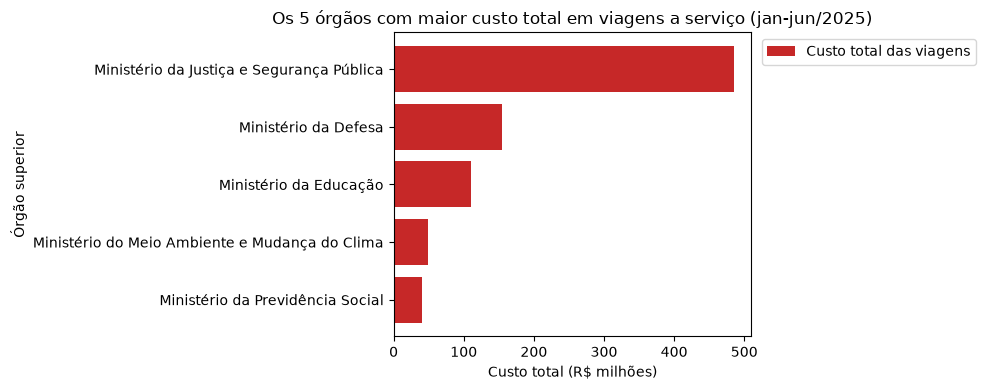

Conclusão: o Ministério da Justiça e Segurança Pública lidera, com R$ 485,7 milhões. Isso equivale a 1,4 vez o custo dos outros 4 órgãos do ranking somados.


In [2]:
tabela = consultar("""
    SELECT nome_orgao_superior AS orgao,
           SUM(valor_total) AS custo_total
    FROM silver_viagem
    WHERE situacao = 'Realizada'
    GROUP BY nome_orgao_superior
    ORDER BY custo_total DESC
    LIMIT 5
""")
tabela["custo_milhoes"] = tabela["custo_total"] / 1_000_000
display(tabela)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(tabela["orgao"], tabela["custo_milhoes"], color="#C62828", label="Custo total das viagens")
ax.invert_yaxis()
ax.set_title("Os 5 órgãos com maior custo total em viagens a serviço (jan-jun/2025)")
ax.set_xlabel("Custo total (R$ milhões)")
ax.set_ylabel("Órgão superior")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  
plt.tight_layout()
plt.show()

lider = tabela.iloc[0]
outros = tabela["custo_total"].iloc[1:].sum()
print(f"Conclusão: o {lider['orgao']} lidera, com R$ {formatar_numero(lider['custo_milhoes'], 1)} milhões. "
      f"Isso equivale a {formatar_numero(lider['custo_total'] / outros, 1)} vez o custo dos outros 4 órgãos do ranking somados.")

## 2 - Os 3 destinos com maior custo médio por viagem? 

,destino,viagens,custo_medio
0,"Brasília/DF, Brasília/DF",283,27401.80
1,Genebra/Suíça,242,25469.22
2,Nova York/Estados Unidos da América,149,21214.19


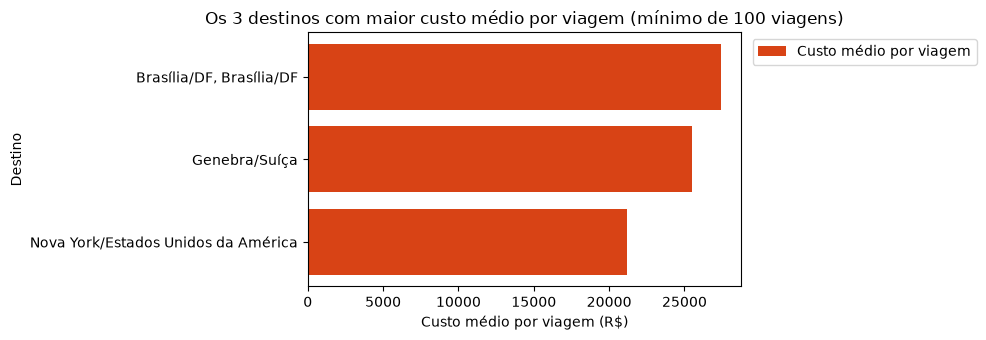

Conclusão: 'Brasília/DF, Brasília/DF' tem o maior custo médio, R$ 27.401,80 por viagem, em 283 viagens. Só entram destinos com 100 viagens ou mais, para a média não ser enganosa.


In [3]:
tabela = consultar("""
    SELECT destinos AS destino,
           COUNT(*) AS viagens,
           ROUND(AVG(valor_total), 2) AS custo_medio
    FROM silver_viagem
    WHERE situacao = 'Realizada'
    GROUP BY destinos
    HAVING COUNT(*) >= 100
    ORDER BY custo_medio DESC
    LIMIT 3
""")
display(tabela)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(tabela["destino"], tabela["custo_medio"], color="#D84315", label="Custo médio por viagem")
ax.invert_yaxis()
ax.set_title("Os 3 destinos com maior custo médio por viagem (mínimo de 100 viagens)")
ax.set_xlabel("Custo médio por viagem (R$)")
ax.set_ylabel("Destino")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)) 
plt.tight_layout()
plt.show()

lider = tabela.iloc[0]
print(f"Conclusão: '{lider['destino']}' tem o maior custo médio, R$ {formatar_numero(lider['custo_medio'])} por viagem, "
      f"em {lider['viagens']} viagens. Só entram destinos com 100 viagens ou mais, para a média não ser enganosa.")

## 3 - A viagem de maior duração e seu custo total?

,id_viagem,orgao,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,384,0.00
1,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,379,120650.00
2,0000000000020793492,Ministério da Justiça e Segurança Pública,2025-01-11,2026-01-15,370,113382.50
3,0000000000020774569,Ministério da Educação,2025-02-26,2026-03-02,370,0.00
4,0000000000020592696,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,367,159044.90


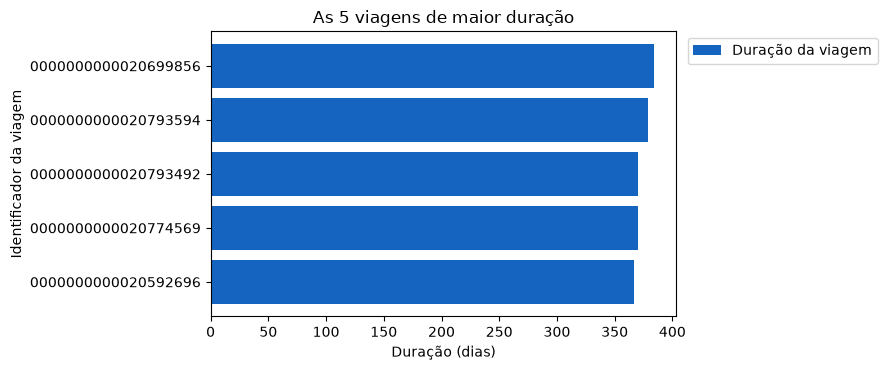

Conclusão: a viagem 0000000000020699856 (Ministério da Previdência Social) é a mais longa, com 384 dias (de 2025-01-13 a 2026-01-31). Custo total registrado: R$ 0,00.


In [4]:
tabela = consultar("""
    SELECT id_viagem,
           nome_orgao_superior AS orgao,
           data_inicio,
           data_fim,
           duracao_dias,
           valor_total
    FROM silver_viagem
    WHERE situacao = 'Realizada' AND duracao_dias IS NOT NULL
    ORDER BY duracao_dias DESC, valor_total DESC
    LIMIT 5
""")
display(tabela)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(tabela["id_viagem"], tabela["duracao_dias"], color="#1565C0", label="Duração da viagem")
ax.invert_yaxis()
ax.set_title("As 5 viagens de maior duração")
ax.set_xlabel("Duração (dias)")
ax.set_ylabel("Identificador da viagem")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  
plt.tight_layout()
plt.show()

maior = tabela.iloc[0]
print(f"Conclusão: a viagem {maior['id_viagem']} ({maior['orgao']}) é a mais longa, com {maior['duracao_dias']} dias "
      f"(de {maior['data_inicio']} a {maior['data_fim']}). Custo total registrado: R$ {formatar_numero(maior['valor_total'])}.")

# Camada Gold com funções de agregação e JOINS:

In [5]:
from banco import conectar

CONSULTA_PAGAMENTO = """
    SELECT p.nome_orgao_pagador,
           p.tipo_pagamento,
           COUNT(*) AS qtd_pagamentos,
           SUM(p.valor) AS total_pago
    FROM silver_pagamento p
    JOIN silver_viagem v ON v.id_viagem = p.id_viagem
    WHERE v.situacao = 'Realizada'
    GROUP BY p.nome_orgao_pagador, p.tipo_pagamento
"""

CONSULTA_TRECHO = """
    SELECT t.meio_transporte,
           t.destino_uf,
           COUNT(*) AS qtd_trechos
    FROM silver_trecho t
    JOIN silver_viagem v ON v.id_viagem = t.id_viagem
    WHERE v.situacao = 'Realizada'
    GROUP BY t.meio_transporte, t.destino_uf
"""

conexao = conectar()
try:
    cursor = conexao.cursor()
    cursor.execute("DROP TABLE IF EXISTS gold_pagamento_resumo")
    cursor.execute("CREATE TABLE gold_pagamento_resumo AS " + CONSULTA_PAGAMENTO)
    cursor.execute("CREATE OR REPLACE VIEW vw_gold_pagamento_resumo AS " + CONSULTA_PAGAMENTO)

    cursor.execute("DROP TABLE IF EXISTS gold_trecho_resumo")
    cursor.execute("CREATE TABLE gold_trecho_resumo AS " + CONSULTA_TRECHO)
    cursor.execute("CREATE OR REPLACE VIEW vw_gold_trecho_resumo AS " + CONSULTA_TRECHO)

    conexao.commit()
    print("Camada Gold criada: 2 tabelas e 2 views.")
except Exception as erro:
    conexao.rollback()
    print("ERRO ao criar a camada Gold:", type(erro).__name__, erro)
finally:
    conexao.close()

Camada Gold criada: 2 tabelas e 2 views.


## Conferência: a tabela e a view foram criadas a partir da mesma consulta, então, neste momento, precisam ter a mesma quantidade de linhas.

In [6]:
conexao = conectar()
cursor = conexao.cursor()
for tabela_gold, visao_gold in [("gold_pagamento_resumo", "vw_gold_pagamento_resumo"),
                                ("gold_trecho_resumo", "vw_gold_trecho_resumo")]:
    cursor.execute(f"SELECT COUNT(*) FROM {tabela_gold}")
    linhas_tabela = cursor.fetchone()[0]
    cursor.execute(f"SELECT COUNT(*) FROM {visao_gold}")
    linhas_view = cursor.fetchone()[0]
    situacao = "OK" if linhas_tabela == linhas_view else "DIFERENTE!"
    print(f"{tabela_gold}: {linhas_tabela} linhas | {visao_gold}: {linhas_view} linhas -> {situacao}")
conexao.close()

gold_pagamento_resumo: 655 linhas | vw_gold_pagamento_resumo: 655 linhas -> OK
gold_trecho_resumo: 201 linhas | vw_gold_trecho_resumo: 201 linhas -> OK


## 4 - Qual o tipo de pagamento com maior valor médio? 

,tipo_pagamento,pagamentos,valor_medio
0,DIÁRIAS,400364,2078.79
1,PASSAGEM,182883,1882.32
2,Serviço correlato: seguro,4789,447.26
3,RESTITUIÇÃO,11574,245.70


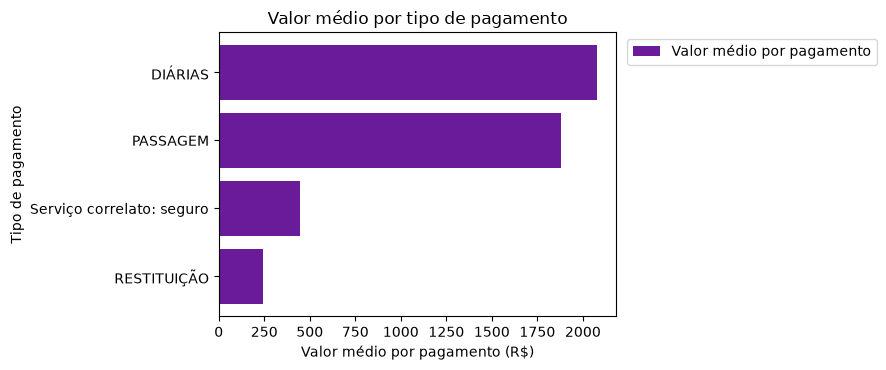

Conclusão: o tipo 'DIÁRIAS' tem o maior valor médio, R$ 2.078,79 por pagamento, em 400.364 pagamentos.


In [7]:
tabela = consultar("""
    SELECT tipo_pagamento,
           SUM(qtd_pagamentos)::INT AS pagamentos,
           ROUND(SUM(total_pago) / SUM(qtd_pagamentos), 2) AS valor_medio
    FROM gold_pagamento_resumo
    GROUP BY tipo_pagamento
    ORDER BY valor_medio DESC
""")
display(tabela)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(tabela["tipo_pagamento"], tabela["valor_medio"], color="#6A1B9A", label="Valor médio por pagamento")
ax.invert_yaxis()
ax.set_title("Valor médio por tipo de pagamento")
ax.set_xlabel("Valor médio por pagamento (R$)")
ax.set_ylabel("Tipo de pagamento")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  # legenda fora do gráfico, para não cobrir as barras
plt.tight_layout()
plt.show()

lider = tabela.iloc[0]
print(f"Conclusão: o tipo '{lider['tipo_pagamento']}' tem o maior valor médio, R$ {formatar_numero(lider['valor_medio'])} "
      f"por pagamento, em {formatar_numero(lider['pagamentos'], 0)} pagamentos.")

## 5 - Qual o meio de transporte mais usado nos trechos? 

,meio_transporte,trechos
0,Veículo Oficial,385734
1,Aéreo,226707
2,Rodoviário,64454
3,Veículo Próprio,42736
4,Inválido,26523
5,Fluvial,8392
6,Ferroviário,868
7,Marítimo,471


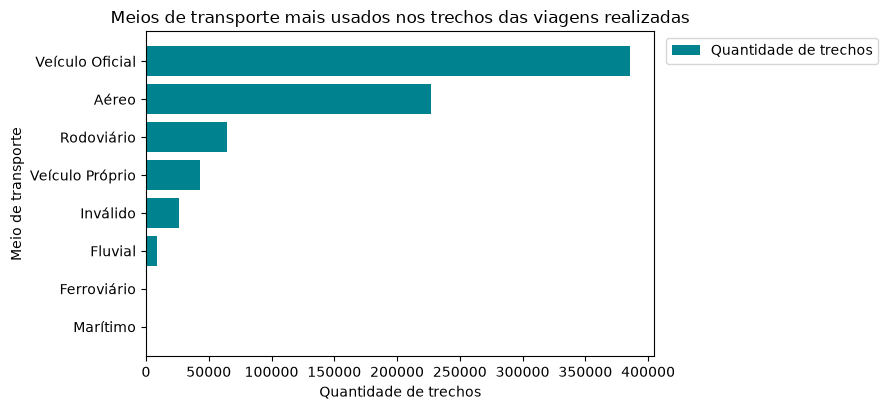

Conclusão: 'Veículo Oficial' é o meio mais usado, com 385.734 trechos (51,0% do total de 755.885).


In [8]:
tabela = consultar("""
    SELECT meio_transporte,
           SUM(qtd_trechos)::INT AS trechos
    FROM gold_trecho_resumo
    GROUP BY meio_transporte
    ORDER BY trechos DESC
""")
display(tabela)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(tabela["meio_transporte"], tabela["trechos"], color="#00838F", label="Quantidade de trechos")
ax.invert_yaxis()
ax.set_title("Meios de transporte mais usados nos trechos das viagens realizadas")
ax.set_xlabel("Quantidade de trechos")
ax.set_ylabel("Meio de transporte")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  
plt.tight_layout()
plt.show()

lider = tabela.iloc[0]
total = tabela["trechos"].sum()
print(f"Conclusão: '{lider['meio_transporte']}' é o meio mais usado, com {formatar_numero(lider['trechos'], 0)} trechos "
      f"({formatar_numero(lider['trechos'] / total * 100, 1)}% do total de {formatar_numero(total, 0)}).")

## 6 - Qual UF de destino aparece em mais trechos? 


,uf,trechos
0,São Paulo,81727
1,Distrito Federal,77962
2,Minas Gerais,50555
3,Rio de Janeiro,43481
4,Paraná,42323
5,Pará,39742
6,Rio Grande do Sul,38397
7,Mato Grosso do Sul,30450
8,Bahia,28141
9,Pernambuco,28117


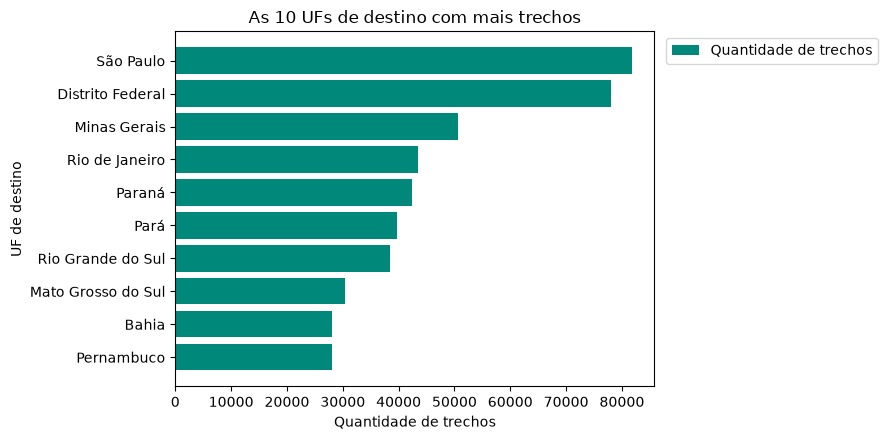

Conclusão: São Paulo é a UF de destino mais frequente, com 81.727 trechos.


In [9]:
tabela = consultar("""
    SELECT destino_uf AS uf,
           SUM(qtd_trechos)::INT AS trechos
    FROM gold_trecho_resumo
    GROUP BY destino_uf
    ORDER BY trechos DESC
    LIMIT 10
""")
display(tabela)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(tabela["uf"], tabela["trechos"], color="#00897B", label="Quantidade de trechos")
ax.invert_yaxis()
ax.set_title("As 10 UFs de destino com mais trechos")
ax.set_xlabel("Quantidade de trechos")
ax.set_ylabel("UF de destino")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  
plt.tight_layout()
plt.show()

lider = tabela.iloc[0]
print(f"Conclusão: {lider['uf']} é a UF de destino mais frequente, com {formatar_numero(lider['trechos'], 0)} trechos.")

## 7 - Qual órgão pagou mais no total ? 

,orgao_pagador,total_pago,total_milhoes
0,Fundo Nacional de Segurança Pública,278288685.42,278.29
1,Sigiloso,199308482.09,199.31
2,Comando da Aeronáutica,81069602.67,81.07
3,Instituto Nacional do Seguro Social,37254697.89,37.25
4,Comando do Exército,36576135.70,36.58


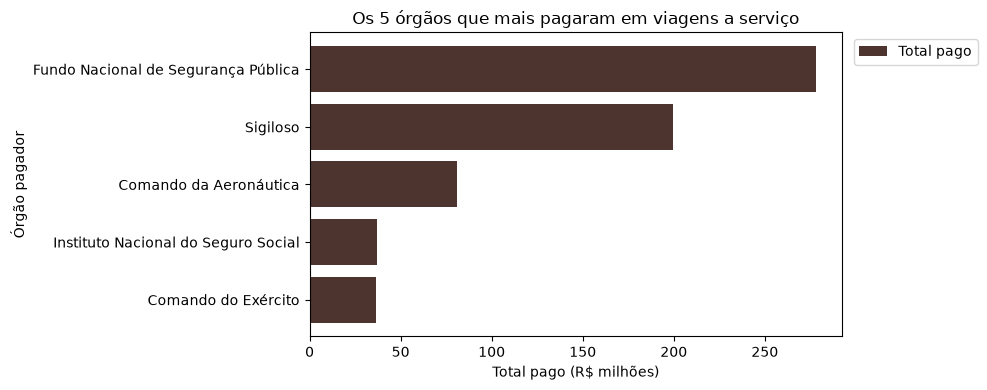

Conclusão: o Fundo Nacional de Segurança Pública foi quem mais pagou, R$ 278,3 milhões.


In [10]:
tabela = consultar("""
    SELECT nome_orgao_pagador AS orgao_pagador,
           SUM(total_pago) AS total_pago
    FROM gold_pagamento_resumo
    GROUP BY nome_orgao_pagador
    ORDER BY total_pago DESC
    LIMIT 5
""")
tabela["total_milhoes"] = tabela["total_pago"] / 1_000_000
display(tabela)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(tabela["orgao_pagador"], tabela["total_milhoes"], color="#4E342E", label="Total pago")
ax.invert_yaxis()
ax.set_title("Os 5 órgãos que mais pagaram em viagens a serviço")
ax.set_xlabel("Total pago (R$ milhões)")
ax.set_ylabel("Órgão pagador")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  
plt.tight_layout()
plt.show()

lider = tabela.iloc[0]
print(f"Conclusão: o {lider['orgao_pagador']} foi quem mais pagou, R$ {formatar_numero(lider['total_milhoes'], 1)} milhões.")

# Decisões e limitações da análise: 

- Filtro das viagens: foram consideradas apenas as viagens com situação 'Realizada' em todas as perguntas da análise.

- Cálculo do custo total: o valor foi obtido somando diárias, passagens e demais despesas, com o desconto dos valores devolvidos. Como o enunciado não especifica uma fórmula, foi adotado esse critério, implementado no arquivo 2_transformar.py.

- Cálculo da duração: a quantidade de dias foi calculada pela diferença entre as datas de término e de início, acrescida de um dia para incluir as duas datas no resultado.

- Destinos (Pergunta 2): 'destinos' é texto livre, e uma mesma cidade pode aparecer repetida na lista. A análise trata cada texto igual como um destino e exige 100 viagens ou mais por destino; Uma melhoria futura seria separar as cidades.

- Órgão pagador (Pergunta 7): existe na base um registro identificado como "Sigiloso", que aparece entre os maiores pagadores. Entretanto, essa identificação não permite saber qual órgão realizou o pagamento.

- Meio de transporte (Pergunta 5): a categoria "Inválido" foi mantida conforme registrada na base original, sem alterações.

- Média por tipo de pagamento (Pergunta 4): a média foi calculada dividindo o valor total pago pela quantidade de pagamentos de cada tipo. Dessa forma, evita-se calcular uma média simples a partir de médias já calculadas.